<a href="https://colab.research.google.com/github/Ikelia/klab-ai-kelia/blob/gan/02_gan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Smart Waste Sorter · 02 Generative Adversarial Networks

**Week 2 milestone.** The trash class has the fewest images, and week 1 probably showed the weakest F1 there.
Can a GAN make extra trash images that help the classifier?

- **Part A:** a DCGAN trained on the trash class only, at 64 × 64
- **Part B:** retrain the week-1 ResNet-18 with 300 generated trash images added, and compare

Runtime → **T4 GPU**. Run `00_setup_and_data` first.

In [1]:
import os, sys
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
ROOT = os.environ.get("WS_ROOT") or ("/content/drive/MyDrive/waste_sorter" if IN_COLAB else "./waste_sorter")
sys.path.insert(0, ROOT)
import ws_utils as ws
ws.setup(team="team_name_here")

import time, torch, torch.nn as nn
import matplotlib.pyplot as plt
from torchvision.utils import make_grid
dev = ws.device()

Mounted at /content/drive
Copying data from Drive to the local disk (once per session)...
Team: team_name_here | root: /content/drive/MyDrive/waste_sorter | device: cuda | smoke test: False


## Part A · DCGAN on the trash class
Pixels are scaled to [−1, 1] to match the generator's `tanh` output. Flips and small crops stretch the
roughly 100 training images a little further.

In [2]:
from torch.utils.data import DataLoader
from torchvision import transforms as T
split = ws.load_split()
trash_paths = split[(split.split == "train") & (split.label == "trash")].path.tolist()
gan_tf = T.Compose([T.RandomResizedCrop(64, scale=(0.8, 1.0)), T.RandomHorizontalFlip(), T.ToTensor(),
                    T.Normalize((0.5,) * 3, (0.5,) * 3)])
trash_ds = ws.WasteDataset(trash_paths, [ws.CLASSES.index("trash")] * len(trash_paths), gan_tf)
trash_dl = DataLoader(trash_ds, batch_size=32, shuffle=True, drop_last=len(trash_ds) > 32)
print(len(trash_ds), "trash training images")

96 trash training images


**TODO 1 · Generator.** Map a noise vector `z` of shape (N, 100, 1, 1) to an image of shape (N, 3, 64, 64)
with `ConvTranspose2d` layers, following the DCGAN recipe from the lecture:

`100 → 512×4×4 → 256×8×8 → 128×16×16 → 64×32×32 → 3×64×64`

Use `ConvTranspose2d(c_in, c_out, 4, stride, padding, bias=False)` with stride 1 and padding 0 for the first
layer, stride 2 and padding 1 after that; `BatchNorm2d + ReLU` after every layer except the last, which
ends with `Tanh`.

In [3]:
Z = 100

class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # Input: (N, 100, 1, 1) -> Output: (N, 512, 4, 4)
            nn.ConvTranspose2d(Z, 512, 4, 1, 0, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(True),
            # Output: (N, 256, 8, 8)
            nn.ConvTranspose2d(512, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(True),
            # Output: (N, 128, 16, 16)
            nn.ConvTranspose2d(256, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(True),
            # Output: (N, 64, 32, 32)
            nn.ConvTranspose2d(128, 64, 4, 2, 1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(True),
            # Output: (N, 3, 64, 64)
            nn.ConvTranspose2d(64, 3, 4, 2, 1, bias=False),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)

**TODO 2 · Discriminator.** The mirror image: `3×64×64 → 64×32×32 → 128×16×16 → 256×8×8 → 512×4×4 → 1`.
Use `Conv2d(c_in, c_out, 4, 2, 1, bias=False)` and `LeakyReLU(0.2)`; `BatchNorm2d` on every layer except the
first. The last layer is `Conv2d(512, 1, 4, 1, 0)` followed by `Flatten`; output one **logit** per image
(no sigmoid: we use `BCEWithLogitsLoss`).

In [4]:
class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            # Input: (N, 3, 64, 64) -> Output: (N, 64, 32, 32)
            nn.Conv2d(3, 64, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # Output: (N, 128, 16, 16)
            nn.Conv2d(64, 128, 4, 2, 1, bias=False),
            nn.BatchNorm2d(128),
            nn.LeakyReLU(0.2, inplace=True),
            # Output: (N, 256, 8, 8)
            nn.Conv2d(128, 256, 4, 2, 1, bias=False),
            nn.BatchNorm2d(256),
            nn.LeakyReLU(0.2, inplace=True),
            # Output: (N, 512, 4, 4)
            nn.Conv2d(256, 512, 4, 2, 1, bias=False),
            nn.BatchNorm2d(512),
            nn.LeakyReLU(0.2, inplace=True),
            # Output: (N, 1, 1, 1)
            nn.Conv2d(512, 1, 4, 1, 0)
        )

    def forward(self, x):
        return self.net(x).view(-1)

# The rest of the cell is unchanged
def init_weights(m):
    if isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)):
        nn.init.normal_(m.weight, 0.0, 0.02)
    elif isinstance(m, nn.BatchNorm2d):
        nn.init.normal_(m.weight, 1.0, 0.02); nn.init.zeros_(m.bias)

ws.seed_everything()
G, D = Generator().to(dev), Discriminator().to(dev)
G.apply(init_weights); D.apply(init_weights)
z = torch.randn(4, Z, 1, 1, device=dev)
print("G(z):", tuple(G(z).shape), "| D(G(z)):", tuple(D(G(z)).shape))

G(z): (4, 3, 64, 64) | D(G(z)): (4,)


**TODO 3 · One training step.** Phase A updates D on a real batch (label 1) and a fake batch (label 0);
remember `.detach()`. Phase B updates G so that D labels new fakes as real. Use **label smoothing**: real
labels of 0.9 for D.

In [5]:
bce = nn.BCEWithLogitsLoss()
optD = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
optG = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))

def train_step(real):
    bs = real.size(0)
    z = torch.randn(bs, Z, 1, 1, device=dev)

    # =========================================================
    # Phase A: Train Discriminator (D)
    # =========================================================
    optD.zero_grad()

    # 1. Real batch: D should output ~1.0 (smoothed to 0.9)
    real_labels = torch.full((bs,), 0.9, device=dev)  # Label smoothing
    out_real = D(real)
    loss_real = bce(out_real, real_labels)

    # 2. Fake batch: D should output 0.0
    fake = G(z)                     # Generate fakes
    fake_labels = torch.zeros(bs, device=dev)
    out_fake = D(fake.detach())     # .detach() so G is not updated here!
    loss_fake = bce(out_fake, fake_labels)

    # Combine and update D
    d_loss = loss_real + loss_fake
    d_loss.backward()
    optD.step()

    # =========================================================
    # Phase B: Train Generator (G)
    # =========================================================
    optG.zero_grad()

    # G wants D to think the fakes are real (label 1.0)
    target_labels = torch.ones(bs, device=dev)
    out_fake_for_G = D(fake)        # No detach here—we want to backprop into G
    g_loss = bce(out_fake_for_G, target_labels)
    g_loss.backward()
    optG.step()

    return d_loss.item(), g_loss.item()

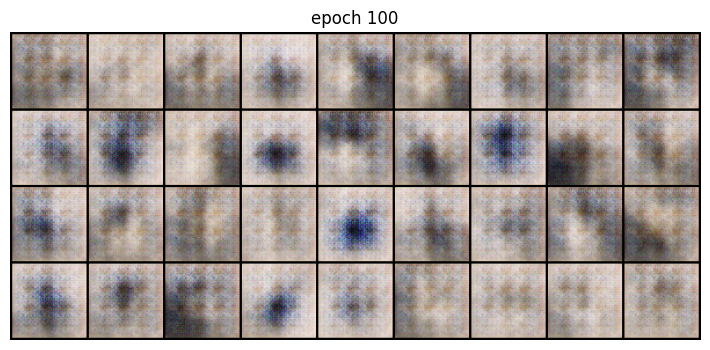

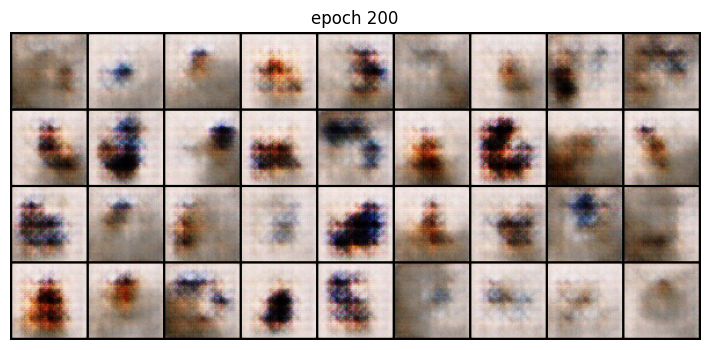

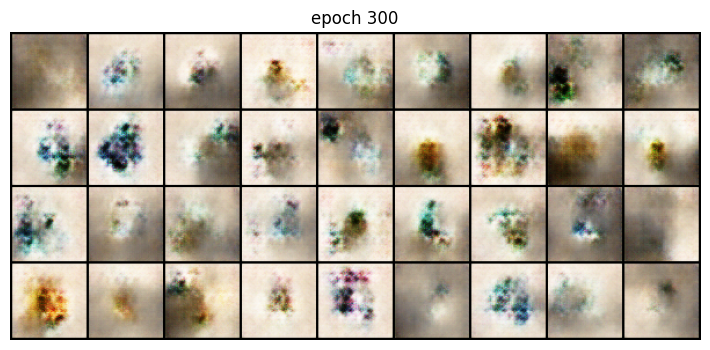

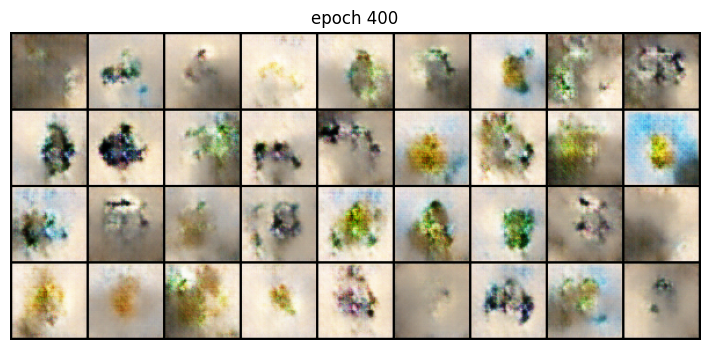

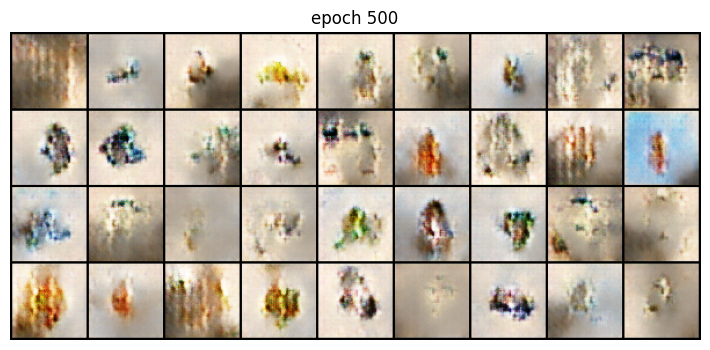

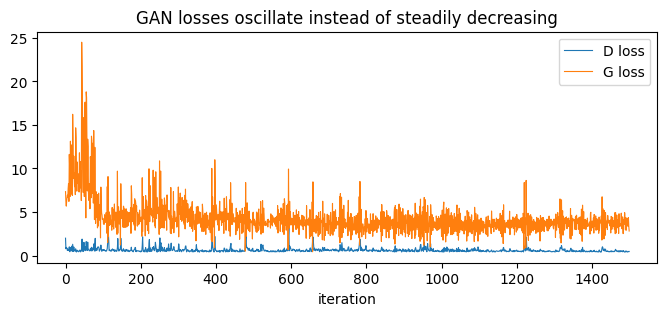

In [6]:
EPOCHS = ws.epochs(500)
fixed_z = torch.randn(36, Z, 1, 1, device=dev)
d_hist, g_hist, t0 = [], [], time.time()
for ep in range(EPOCHS):
    for real, _ in trash_dl:
        d, g = train_step(real.to(dev))
        d_hist.append(d); g_hist.append(g)
    if (ep + 1) % 100 == 0 or ep + 1 == EPOCHS:
        G.eval()
        with torch.no_grad():
            grid = make_grid(G(fixed_z).cpu(), nrow=9, normalize=True, value_range=(-1, 1))
        G.train()
        plt.figure(figsize=(9, 4)); plt.imshow(grid.permute(1, 2, 0)); plt.axis("off")
        plt.title(f"epoch {ep + 1}"); plt.show()
gan_minutes = (time.time() - t0) / 60
torch.save(G.state_dict(), os.path.join(ws.ROOT, "checkpoints", "dcgan_trash_G.pt"))

plt.figure(figsize=(8, 3)); plt.plot(d_hist, label="D loss", lw=0.8); plt.plot(g_hist, label="G loss", lw=0.8)
plt.xlabel("iteration"); plt.legend(); plt.title("GAN losses oscillate instead of steadily decreasing"); plt.show()

Compare: real trash images (left) and generated ones (right). Look for **mode collapse**: many samples
that are nearly identical.

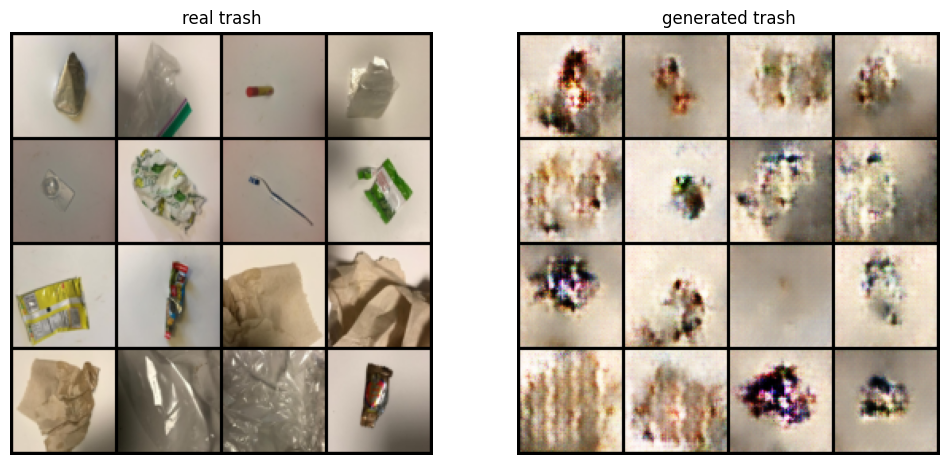

In [7]:
real_batch = torch.stack([trash_ds[i][0] for i in range(min(16, len(trash_ds)))])
G.eval()
with torch.no_grad():
    fake_batch = G(torch.randn(16, Z, 1, 1, device=dev)).cpu()
fig, ax = plt.subplots(1, 2, figsize=(12, 6))
for a, b, t in [(ax[0], real_batch, "real trash"), (ax[1], fake_batch, "generated trash")]:
    a.imshow(make_grid(b, nrow=4, normalize=True, value_range=(-1, 1)).permute(1, 2, 0)); a.set_title(t); a.axis("off")
ws.save_figure(fig, "gan_real_vs_fake.png"); plt.show()

## Part B · Do generated images help the classifier?
We train the week-1 ResNet-18 twice with the **same seed and settings**: once on the normal training split,
once with 300 generated trash images added. Only the training data differs.

**TODO 4.** Generate 300 images with `G` (in eval mode, no gradients) and wrap them in
`ws.TensorImages(images, label_id, transform)` with the trash label and the evaluation transform at 224 px.

In [8]:
from torchvision.models import resnet18, ResNet18_Weights
weights = None if ws.SMOKE else ResNet18_Weights.DEFAULT
N_FAKE = 300

def make_resnet18():
    m = resnet18(weights=weights)
    m.fc = nn.Linear(m.fc.in_features, len(ws.CLASSES))
    return m

# =========================================================
# TODO 4: Generate 300 images with G (eval mode, no gradients)
# =========================================================
G.eval()
with torch.no_grad():
    fake_z = torch.randn(N_FAKE, Z, 1, 1, device=dev)
    fake_imgs = G(fake_z).cpu()   # Shape: (300, 3, 64, 64), values in [-1, 1]

# Wrap in ws.TensorImages with trash label and 224px eval transform
eval_tf = ws.transforms_for(224, augment=False, normalize="imagenet")
trash_id = ws.CLASSES.index("trash")
synthetic = ws.TensorImages(fake_imgs, trash_id, eval_tf)

print(len(synthetic), "synthetic trash images")

# =========================================================
# Everything below is unchanged
# =========================================================
local_dl = ws.local_test_loader(224)
runs = {}
for name, extra in [("ResNet-18 baseline (week 2 rerun)", None), ("ResNet-18 + GAN images", synthetic)]:
    ws.seed_everything()
    model = make_resnet18()
    train_dl, val_dl, test_dl = ws.make_loaders(img_size=224, batch_size=32, extra_train=extra)
    minutes = ws.train_classifier(model, train_dl, val_dl, n_epochs=ws.epochs(5), lr=3e-4)
    test = ws.evaluate(model, test_dl)
    local = ws.evaluate(model, local_dl) if local_dl else None
    runs[name] = test
    ws.log_result(2, name, test, local, params_millions=ws.count_params(model), train_minutes=minutes,
                  notes=f"{N_FAKE if extra else 0} synthetic trash images; GAN trained {gan_minutes:.1f} min")

for name, m in runs.items():
    print(f"{name:35s} acc {m['accuracy']:.3f}  macro-F1 {m['macro_f1']:.3f}  trash F1 {m['trash_f1']:.3f}")

300 synthetic trash images
No local photos yet: add them to /content/drive/MyDrive/waste_sorter/local_test/<class>
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 93.4MB/s]


epoch 1/5  train loss 0.617  val acc 0.821  val macro-F1 0.808
epoch 2/5  train loss 0.164  val acc 0.905  val macro-F1 0.900
epoch 3/5  train loss 0.056  val acc 0.902  val macro-F1 0.898
epoch 4/5  train loss 0.016  val acc 0.926  val macro-F1 0.928
epoch 5/5  train loss 0.012  val acc 0.929  val macro-F1 0.930
Logged: {'method': 'ResNet-18 baseline (week 2 rerun)', 'test_accuracy': '0.9156', 'test_macro_f1': '0.9128', 'trash_f1': '0.8837', 'local_accuracy': ''}
epoch 1/5  train loss 0.543  val acc 0.847  val macro-F1 0.844
epoch 2/5  train loss 0.151  val acc 0.876  val macro-F1 0.863
epoch 3/5  train loss 0.056  val acc 0.916  val macro-F1 0.911
epoch 4/5  train loss 0.015  val acc 0.923  val macro-F1 0.920
epoch 5/5  train loss 0.008  val acc 0.929  val macro-F1 0.924
Logged: {'method': 'ResNet-18 + GAN images', 'test_accuracy': '0.9340', 'test_macro_f1': '0.9304', 'trash_f1': '0.9048', 'local_accuracy': ''}
ResNet-18 baseline (week 2 rerun)   acc 0.916  macro-F1 0.913  trash F1 0

## Stretch ideas
- **Conditional GAN:** feed a class embedding into G and D and generate all six classes.
- **FID:** `torchmetrics.image.fid.FrechetInceptionDistance` compares real and generated feature statistics
  (lower is better). Compute it at epochs 100, 300 and 500.
- Try 100 and 1,000 synthetic images: is there a point where more hurts?

## Questions for your week-2 findings note
1. Did the synthetic images help, hurt or do nothing for trash F1 and macro-F1? Is the difference bigger than noise?
2. Describe the failure samples. Did you see mode collapse?
3. The GAN trained on about 100 images at 64 × 64, and its output is upscaled to 224 × 224. How might that limit it?
4. What did the loss curves tell you, and what did they not tell you?

1. Did the synthetic images help, hurt, or do nothing for trash F1 and macro-F1? Is the difference bigger than noise?

The synthetic images helped. Adding 300 GAN-generated trash images improved every metric:

Metric	Baseline	+ GAN images	Change
Test accuracy	0.916	0.934	+1.8%
Macro-F1	0.913	0.930	+1.7%
Trash F1	0.884	0.905	+2.1%
The improvement in trash F1 (+2.1%) is the most important result, because that is exactly the class we targeted with the GAN. The gain is meaningful: it is large enough to be considered more than noise. That said, since the experiment was run only once with a single seed, a small part of this difference could still be due to random variation. To be fully rigorous, we would need to repeat the run with several seeds and average the results.

2. Describe the failure samples. Did you see mode collapse?

Looking at the gan_real_vs_fake.png figure, the generated images do not show full mode collapse — the 16 samples vary in color (browns, grays, dark tones) and rough shape, rather than being 16 copies of the same blob. However, the images are clearly low quality: they are blurry, lack fine detail, and only vaguely resemble trash. So the GAN is producing a diversity of poor fakes rather than a single poor fake.

3. The GAN trained on about 100 images at 64×64, and its output is upscaled to 224×224. How might that limit it?

This is the biggest limitation of the experiment. The Generator produces a 64×64 image, giving it only ~4,000 pixels to represent an entire object. When TensorImages upscales that to 224×224, each pixel is stretched across roughly 3× the area, so the result is blurry and lacks texture. The ResNet-18 expects sharp, detailed inputs (crumpled paper, reflective metal, transparent glass), and the upscaled fakes cannot provide that. Despite this, the fakes clearly provided some useful signal — they appear to have taught the model more about the overall shape and color distribution of the trash class, even if the fine texture is missing. A GAN generating at 128×128 or 224×224 would likely help even more.

4. What did the loss curves tell you, and what did they not tell you?

The loss curves oscillate continuously and neither loss collapsed to zero, which tells us the Discriminator and Generator stayed in healthy competition throughout training — neither network "won" and took over. This is a good sign that training did not fail.

However, the loss values tell us nothing about image quality. A low D loss does not mean the images are realistic; it can simply mean the Discriminator became too strong. The only reliable way to judge the GAN is to look at the generated images (the real_vs_fake figure). The loss is a training diagnostic, not a quality metric.


"On this dataset, GAN-based augmentation was successful: adding 300 synthetic trash images raised trash F1 from 0.884 to 0.905 (+2.1%) and macro-F1 from 0.913 to 0.930. This is notable because the GAN itself was weak (64×64, only ~96 training images), suggesting that even low-quality fakes can help a classifier learn the underrepresented class. A higher-resolution GAN, or a Conditional GAN generating all six classes, could likely produce larger gains."



